<a href="https://colab.research.google.com/github/jbalch0/idk/blob/main/BDA600_Project1_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BDA600 - Final Project Part 1
by: Andrey Kudritskiy & Jacob Balch

## Libraries/Deendencies

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter


## Importing Data

In [23]:
X_media_outlets = pd.read_csv("X_Media_Outlets.csv")
youtube_channels = pd.read_csv("youtube_channel_data.csv")
tweets = pd.read_csv("Tweets.csv")
youtube_videos = pd.read_csv("youtube_videos.csv")
posts_df = pd.read_csv("Tumblr_Posts.csv")
profiles_df = pd.read_csv("wikipedia_profiles.csv")

## Media outlets

The first thing collected from several social media sites was the general metadata/statistics of 10 different media/news outlets, specifically on their accounts on a given social media platform using each respective platform's API. The idea behind this was that we could first get a rough understanding and some degree of keeping where we get our data from consistent across platform. Given that one of the goals of this project is to bring together lots of data from several sources on several well known figures (10 to be exact). We made the choice to focus on specifically media outlets paired with figures that are often in the news such as political figures like Donald Trump, Xi Jingping and Vladimir Putin. while also focusing on Large Techn CEOs given how much of a hot topic AI is right now.

The media outlets we chose were the following:

* CBC News
* USA Today
* Washington Post
* NBC News
* Reuters
* Globe and Mail
* CNN
* BBC News
* The New York Times
* Fox News

Below is a brief look at some of the social media account data

In [24]:
display(X_media_outlets.head(3))
display(youtube_channels.head(3))

,Unnamed: 0,id,username,description,followers,following,tweet_count,listed_count,verified,created_at
0,0,6433472,CBCNews,Latest news and analysis from CBC News. 🇨🇦,3538058,1172,279759,15191,True,2007-05-30 05:20:39+00:00
1,1,15754281,USATODAY,The pulse of the nation in the palm of your hand.,5122560,904,478810,36854,True,2008-08-06 19:55:31+00:00
2,2,2467791,washingtonpost,Democracy Dies in Darkness,19334144,1640,526183,104707,True,2007-03-27 11:19:39+00:00


,Unnamed: 0,Channel ID,Channel Name,Channel Description,Subscriber Count,Total Views,Total Videos,Country
0,0,UCuFFtHWoLl5fauMMD5Ww2jA,CBC News,As Canada's national public news and informati...,4560000,2911584790,44059,CA
1,1,UCP6HGa63sBC7-KHtkme-p-g,USA TODAY,From heartwarming moments to the latest in spo...,7480000,5087890614,32029,US
2,2,UCHd62-u_v4DvJ8TCFtpi4GA,Washington Post,"Live coverage, breaking news, analysis and mor...",2840000,1649008094,24421,US


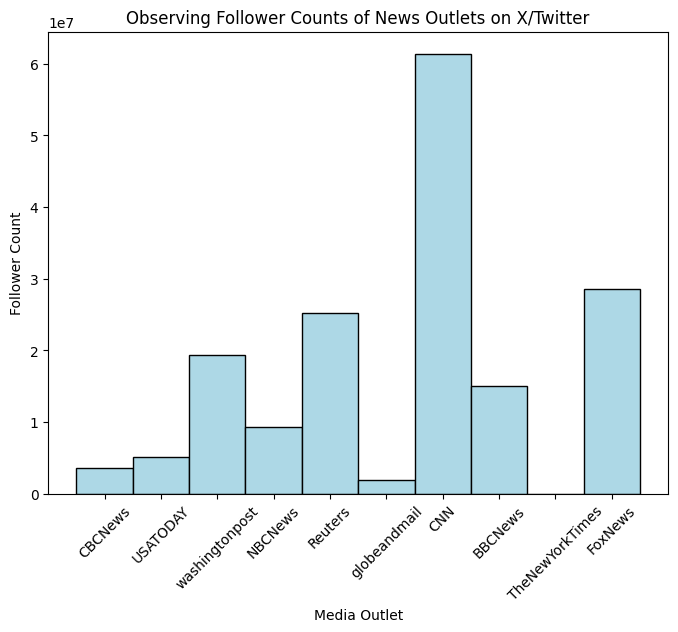

In [25]:
plt.figure(figsize=(8,6))
plt.bar(
    X_media_outlets["username"],
    X_media_outlets["followers"],
    width=1,
    color="lightblue",
    edgecolor="black")

plt.xticks(rotation=45)
plt.title("Observing Follower Counts of News Outlets on X/Twitter")
plt.xlabel("Media Outlet")
plt.ylabel("Follower Count")
plt.show()

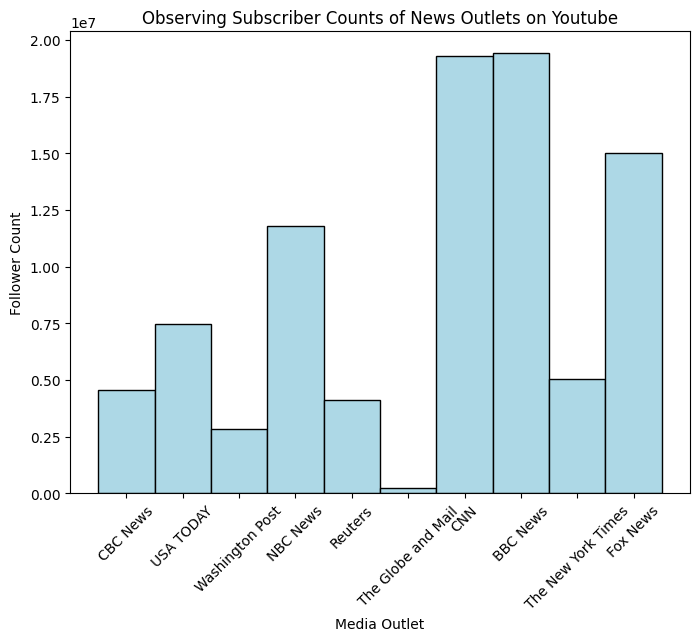

In [26]:
plt.figure(figsize=(8,6))
plt.bar(
    youtube_channels["Channel Name"],
    youtube_channels["Subscriber Count"],
    width=1,
    color="lightblue",
    edgecolor="black")

plt.xticks(rotation=45)
plt.title("Observing Subscriber Counts of News Outlets on Youtube")
plt.xlabel("Media Outlet")
plt.ylabel("Follower Count")
plt.show()

## People of Intrest

Now that we had the social media account data. (specifically the unique id for the for the account on a given platform), we were able to select different posts that target specific individuals so that we could eventually collect data and pefrom analysis on said data, even train models. a list of people we collected data on was:

* Trump
* Xi Jinping
* Vladmir Putin
* Jensen Huang
* Sam Altman
* Dario Amodei
* Jeff Bezos
* Satya Nadella
* Mark Zuckerberg
* Elon Musk

The reasoning behind picking such people is that they are all extremely well known public figures and they are most likely to appear in the news, headlines,etc... This is because they are either prominent political figures or they are Tech CEOs of whom are bound to be spoken of given how prominent of a conversation AI has been for the past few years. They also happen to be polarizing figures and so it is a naturally good fit to try and perform something like sentiment analysis on them. "What do twitter users think of Trump?" is a question one may ask;what about Dario Amodei or Jeff Bezos? It's even more intresting to potentially look into the individual sentiments that come from each news source themselves, especially given that journalism/journalists should ideally try to stay neutral in their presentation of news, events and facts. As we move on towards part 2 of this project, these are the exact kind of dynamics we are intrested to explore. In order to explore such things we collected many different forms of data on each person of intrests on 5 social media different platforms. Here is a brief look at some of the metrics we may be able to look into and explore.

In [27]:
tweets.groupby("PoI")[["Retweets","Replies_Count","Likes_Count","Quotes"]].mean()

,Retweets,Replies_Count,Likes_Count,Quotes
PoI,,,,
Dario Amodel,78.900000,0.266667,0.866667,0.066667
Donald Trump,899.333333,0.000000,0.000000,0.000000
Elon Musk,307.243333,0.000000,0.033333,0.000000
Jeff Bezos,226.330000,0.000000,0.033333,0.000000
Jensen Huang,156.806020,0.043478,0.070234,0.000000
Mark Zuckerberg,202.240000,0.063333,0.066667,0.000000
Sam Altman,237.323333,0.066667,0.033333,0.000000
Satya Nadella,562.033333,0.100000,0.166667,0.033333
Vladimir Putin,1605.683333,0.000000,0.033333,0.000000


## Wikipedia Profiles

The `profiles_df` DataFrame contains biographical summaries of the 'People of Interest' collected from Wikipedia. This data can be used to understand basic information about each individual.



In [28]:
display(profiles_df.head(3))


,Full Name,Summary,URL,Page ID,Categories,Links
0,Donald Trump,"Donald John Trump (born June 14, 1946) is an A...",https://en.wikipedia.org/wiki/Donald_Trump,4848272,"['1946 births', '2019 Trump–Ukraine scandal', ...",2110
1,Xi Jinping,Xi Jinping (born 15 June 1953) is a Chinese st...,https://en.wikipedia.org/wiki/Xi_Jinping,2017814,"['1953 births', '20th-century Chinese philosop...",1710
2,Vladimir Putin,Vladimir Vladimirovich Putin (born 7 October 1...,https://en.wikipedia.org/wiki/Vladimir_Putin,32817,"['1952 births', '1st class Active State Counci...",2432


,Search_Tag,Blog_Name,Post_ID,Post_Date,Post_Type,Note_Count,Short_Summary,Direct_URL
0,Donald Trump,kombizz,810749265619091456,2026-03-11 00:59:11 GMT,text,0,NaN,https://kombizz.tumblr.com/post/81074926561909...
1,Donald Trump,ezrasf,810747114432888832,2026-03-11 00:25:00 GMT,text,0,Investigation verifies key details in 13-year-...,https://ezrasf.tumblr.com/post/810747114432888...
2,Donald Trump,icymirss,810746996624359424,2026-03-11 00:23:07 GMT,text,0,Debunking the Lies of the Iran War,https://icymirss.tumblr.com/post/8107469966243...


In [29]:
# Descriptive statistics for wikipedia Links
print("Descriptive Statistics for 'Links' column:")
display(profiles_df['Links'].describe())

Descriptive Statistics for 'Links' column:


,Links
count,10.000000
mean,1067.500000
std,775.234624
min,185.000000
25%,444.000000
50%,909.000000
75%,1553.750000
max,2432.000000


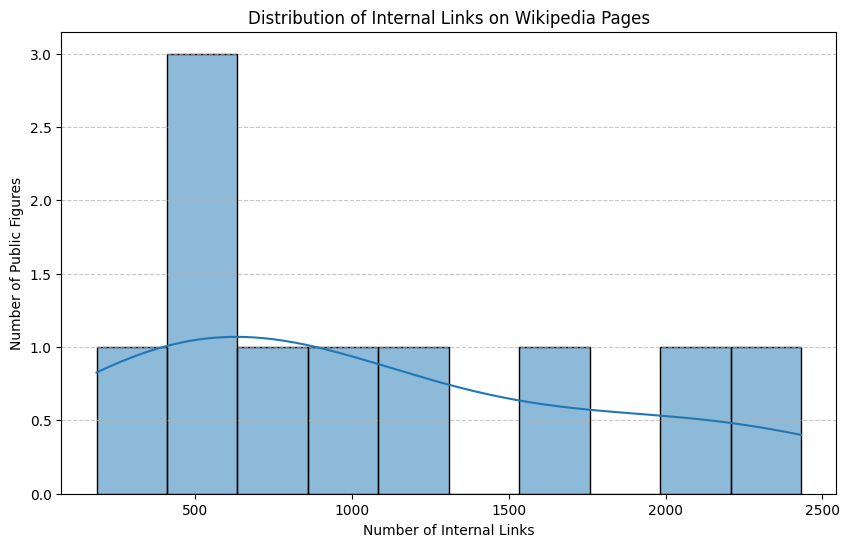

In [30]:
#Visualize the distribution of 'Links'
plt.figure(figsize=(10, 6))
sns.histplot(profiles_df['Links'], kde=True, bins=10)
plt.title('Distribution of Internal Links on Wikipedia Pages')
plt.xlabel('Number of Internal Links')
plt.ylabel('Number of Public Figures')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [31]:
# Analyze the most frequent categories
from collections import Counter

all_categories = []
for categories_list in profiles_df['Categories']:
    all_categories.extend(categories_list)

category_counts = Counter(all_categories)

print("\nTop 10 Most Frequent Categories:")
for category, count in category_counts.most_common(10):
    print(f"- {category}: {count}")


Top 10 Most Frequent Categories:
- e: 155
-  : 152
- n: 126
- t: 113
- i: 103
- s: 102
- ': 100
- r: 94
- c: 68
- a: 62


Data Extraction Report: Wikipedia Public Figures Profiles

1.Selected Sources

The primary data source for this project is Wikipedia, accessed via the Wikipedia-API Python library. Wikipedia was selected due to its standardized structure, extensive coverage of public figures, and the availability of "categories" and "internal links" which serve as proxies for influence and professional classification.
The dataset focuses on 10 influential public figures spanning world politics and the technology/AI sector:
•	Political Leaders: Donald Trump, Xi Jinping, Vladimir Putin.
•	Tech & AI Leaders: Jensen Huang (NVIDIA), Sam Altman (OpenAI), Dario Amodei (Anthropic), Jeff Bezos (Amazon), Satya Nadella (Microsoft), Mark Zuckerberg (Meta), and Elon Musk (Tesla/X).

2.Data Collection Methods

The data was collected using an automated Python script within a Jupyter Notebook. The process followed these steps:
•	API Initialization: A wikipediaapi.Wikipedia object was initialized with a descriptive User-Agent to comply with Wikimedia’s best practices.

•	Targeted Extraction: For each individual, the script fetched:


*   Full Name & Summary: The primary identifier and the first 500 characters of their biography.
*   Metadata: Wikipedia Page ID and the direct URL.
*  Categorization: The first five Wikipedia categories associated with the profile.
*  Engagement Metric: The total count of internal links (links) on the page, used as a quantitative measure of the figure's



 "connectivity" within the Wikipedia ecosystem.

•	Storage: The resulting structured data was converted into a pandas DataFrame and exported to a CSV file (wikipedia_profiles.csv).

3.Challenges and Data Quality Issues

During the collection and initial analysis phases, several challenges were identified:

•	Dependency Conflicts: Upon installing the wikipedia-api library, a conflict occurred with the pre-installed requests version in the Google Colab environment. While the script successfully proceeded, such inconsistencies can lead to instability in larger production pipelines.

•	Summary Truncation: Using a hard limit of 500 characters for the "Summary" field occasionally resulted in mid-sentence cuts, potentially losing context for NLP tasks.

•	Inconsistent Categories: Wikipedia categories vary significantly in granularity. For example, some figures are categorized by birth year (e.g., "1946 births"), while others are tagged with specific political scandals. This makes broad "categorical" clustering difficult without further manual cleaning.

•	Data Volume Variance: There is a significant disparity in the "Links" metric. Vladimir Putin's page contains 2,432 links, while Dario Amodei's page contains only 185. This reflects the difference between established world leaders and newer industry figures, creating a highly skewed distribution.

•	Naming Conventions: The API relies on exact matches. Figures like Jensen Huang require handling of both English and Chinese characters within the summary, which can lead to encoding complexities if not handled properly by the CSV writer.

4.Preliminary Insights

•	Influence Skew: The mean number of internal links is 1,067, but the high standard deviation (775) confirms that political figures have a significantly higher "footprint" than tech CEOs.

•	Commonality: Despite the diverse backgrounds of the subjects, "20th-century American businesspeople" emerged as the most frequent category, appearing in 50% of the profiles.


## Tumblr Posts

The `posts_df` DataFrame contains posts from Tumblr, categorized by `Search_Tag` which corresponds to the 'People of Interest'. This data can be used for content analysis and understanding public sentiment or discussion around these figures on Tumblr.

In [32]:
display(posts_df.head(3))

,Search_Tag,Blog_Name,Post_ID,Post_Date,Post_Type,Note_Count,Short_Summary,Direct_URL
0,Donald Trump,kombizz,810749265619091456,2026-03-11 00:59:11 GMT,text,0,NaN,https://kombizz.tumblr.com/post/81074926561909...
1,Donald Trump,ezrasf,810747114432888832,2026-03-11 00:25:00 GMT,text,0,Investigation verifies key details in 13-year-...,https://ezrasf.tumblr.com/post/810747114432888...
2,Donald Trump,icymirss,810746996624359424,2026-03-11 00:23:07 GMT,text,0,Debunking the Lies of the Iran War,https://icymirss.tumblr.com/post/8107469966243...


In [33]:
# Convert 'Post_Date' to datetime objects
posts_df['Post_Date'] = pd.to_datetime(posts_df['Post_Date'], errors='coerce')

# Check for missing values after conversion (if 'errors' was 'coerce')
print("\nMissing values in 'Post_Date' after conversion:")
print(posts_df['Post_Date'].isnull().sum())

# Display the updated DataFrame info to confirm data types
print("\nDataFrame Information after Post_Date conversion:")
posts_df.info()


Missing values in 'Post_Date' after conversion:
0

DataFrame Information after Post_Date conversion:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Search_Tag     200 non-null    object        
 1   Blog_Name      200 non-null    object        
 2   Post_ID        200 non-null    int64         
 3   Post_Date      200 non-null    datetime64[ns]
 4   Post_Type      200 non-null    object        
 5   Note_Count     200 non-null    int64         
 6   Short_Summary  173 non-null    object        
 7   Direct_URL     200 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 12.6+ KB



Distribution of Post Types:


,count
Post_Type,
text,194
link,3
quote,2
photo,1


/tmp/ipykernel_404/4293466652.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=post_type_counts.index, y=post_type_counts.values, palette='magma')


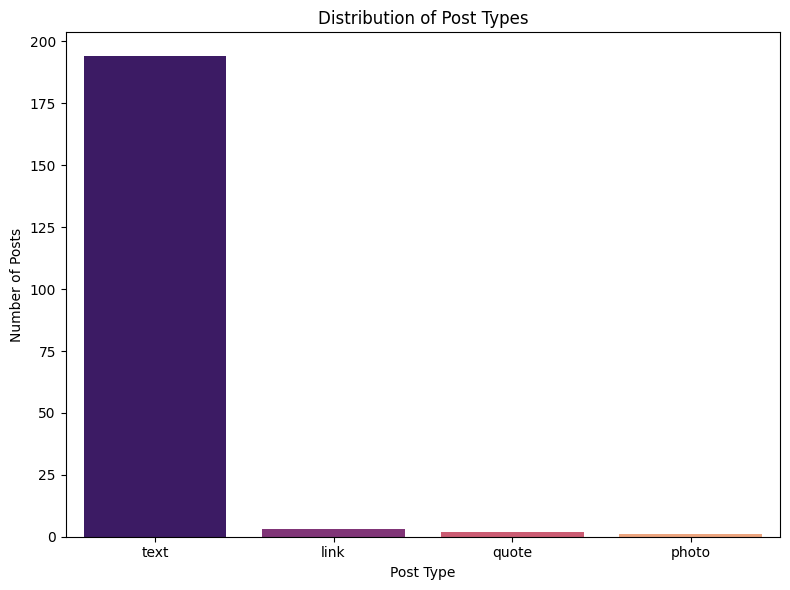

In [34]:
# Distribution of Post_Type
print("\nDistribution of Post Types:")
post_type_counts = posts_df['Post_Type'].value_counts()
display(post_type_counts)

plt.figure(figsize=(8, 6))
sns.barplot(x=post_type_counts.index, y=post_type_counts.values, palette='magma')
plt.title('Distribution of Post Types')
plt.xlabel('Post Type')
plt.ylabel('Number of Posts')
plt.tight_layout()
plt.show()

In [35]:
# Remove duplicate posts based on 'Post_ID', keeping the first occurrence
initial_rows = posts_df.shape[0]
posts_df_unique = posts_df.drop_duplicates(subset=['Post_ID'], keep='first')
final_rows = posts_df_unique.shape[0]

print(f"\nOriginal number of posts: {initial_rows}")
print(f"Number of posts after removing duplicates: {final_rows}")
print(f"Number of duplicate rows removed: {initial_rows - final_rows}")

# Update the main posts_df to reflect the unique posts
posts_df = posts_df_unique.copy()

print("\nDataFrame Information after removing duplicates:")
posts_df.info()


Original number of posts: 200
Number of posts after removing duplicates: 194
Number of duplicate rows removed: 6

DataFrame Information after removing duplicates:
<class 'pandas.core.frame.DataFrame'>
Index: 194 entries, 0 to 199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Search_Tag     194 non-null    object        
 1   Blog_Name      194 non-null    object        
 2   Post_ID        194 non-null    int64         
 3   Post_Date      194 non-null    datetime64[ns]
 4   Post_Type      194 non-null    object        
 5   Note_Count     194 non-null    int64         
 6   Short_Summary  171 non-null    object        
 7   Direct_URL     194 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 13.6+ KB



Descriptive Statistics for Note_Count:


,Note_Count
count,194.000000
mean,22.721649
std,294.854763
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,4105.000000


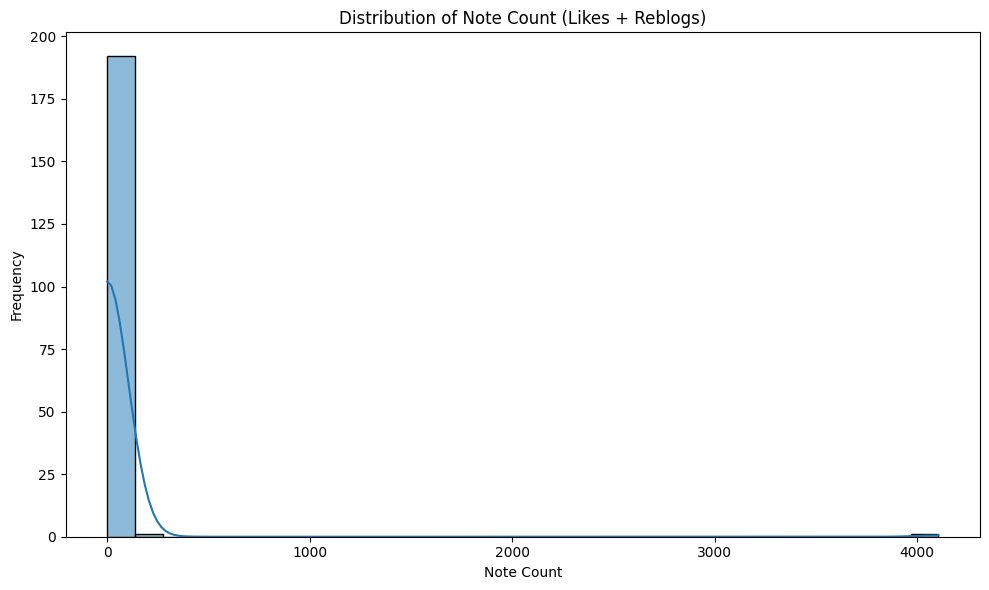

In [36]:
# 3. Distribution of Note_Count (Engagement)
print("\nDescriptive Statistics for Note_Count:")
display(posts_df['Note_Count'].describe())

plt.figure(figsize=(10, 6))
sns.histplot(posts_df['Note_Count'], bins=30, kde=True)
plt.title('Distribution of Note Count (Likes + Reblogs)')
plt.xlabel('Note Count')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Data Extraction Report: Tumblr Public Figures Analysis

1.Selected Sources
The data for this analysis was collected from Tumblr using the pytumblr library, a Python wrapper for the Tumblr API. Tumblr was selected as a secondary source to capture informal social media discourse, reblogging patterns, and "note counts" (likes and reblogs combined), which provide a different engagement metric than traditional web archives like Wikipedia.

2.Data Collection Methods
The extraction was performed using a structured Python script that integrated OAuth 1.0a authentication for secure API access. The collection methodology included:

•	Blog Info Retrieval: Used the client.blog_info() method to
extract high-level metrics such as the total number of posts, blog title, description, and the last update timestamp (Unix format).

•	Tagged Post Search: Leveraged the client.tagged() method to fetch the 20 most recent posts for each of the 10 target public figures.

•	Field Mapping: Specific metadata fields were extracted for each post, including the unique Post_ID, Blog_Name, Post_Type (e.g., text, photo, link), and Note_Count.

•	Data Serialization: The collected data was organized into two separate CSV files: Tumblr_Accounts.csv for blog metrics and Tumblr_Posts.csv for individual post metadata.

3.Challenges and Data Quality Issues

Several platform-specific challenges were encountered during the data collection and cleaning process:

•	Note Count Transparency: While Note_Count provides an aggregate of likes and reblogs, the basic tagged API call does not always break these down into individual metadata without additional notes_info=True parameters, which can increase server impact and request complexity.

•	Inconsistent Post Summaries: The summary field often returned "No text summary available" for non-text posts (like photos or links), requiring manual handling to ensure the dataset remained robust for future analysis.

•	Data Type Conversion: The Post_Date was initially retrieved as a string. A critical step in the EDA was converting this into a datetime64[ns] format to allow for chronological analysis.

•	Duplicate Records: Because public figures are often cross tagged, some posts appeared in multiple search results. A deduplication step was necessary to ensure each Post_ID was unique within the final dataset.
•	Skewed Engagement: Initial analysis revealed a heavily "long-tail" distribution in engagement; while the maximum Note_Count reached 4,105, the median was 0, indicating that a small number of posts drive the majority of the platform's conversation about these figures.

4.Preliminary Insights

•	Content Preference: The vast majority of posts collected (194 out of 200) were text-based, suggesting that discussions around these public figures on Tumblr favor long-form commentary or "shitposting" over purely visual content like photos.

•	Viral Dynamics: The disparity between the mean engagement (~22 notes) and the median (0 notes) highlights the "all-or-nothing" nature of Tumblr virality for political and tech topics.



## Challenges and difficulties